### NLP LAB 7
### U24AI041
### UMANG PATEL


# 
You have to design a POS tagger for Hindi. You are given the POS tagged files with train, dev, 
and test splits. Implement the following algorithms. Calculate the probabilities from the train data and evaluate them on dev and test data. Report 
the F1-score for each tag. Compare the performance of all algorithms. Plot charts to compare 
the performance on each tag.

## Q1:
Naive Bayes Classifier: You need to predict the tag of each word. The features for each 
word are: 

* #### Loading


In [3]:
from collections import Counter
from pathlib import Path
from math import log
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

LAB_DIR = Path.cwd() if Path.cwd().name.lower() == "lab 7" else Path.cwd() / "Lab 7"
OUTPUT_DIR = LAB_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BOS = "<BOS>"
EOS = "<EOS>"
ALPHA = 0.1

In [2]:
def load_tagged_sentences(path):
    sentences = []
    sentence = []
    with path.open(encoding="utf-8") as data_file:
        for line_number, line in enumerate(data_file, start=1):
            line = line.rstrip("\r\n")
            if not line.strip():
                if sentence:
                    sentences.append(sentence)
                    sentence = []
                continue
            fields = line.rsplit("\t", 1)
            if len(fields) != 2:
                raise ValueError(f"Invalid token/tag row in {path.name}:{line_number}")
            word, tag = fields
            sentence.append((word, tag))
    if sentence:
        sentences.append(sentence)
    return sentences



* ### F1: Length feature
    If a word has more than four characters, its feature is **MORE**; otherwise it is **LESS**.
* ### F2:
    Actual Word  
* ### F3:
    Previous Word
* ### F4:
    Next Word 
* ### F5:
    Previous Tag 

In [4]:
train_sentences = load_tagged_sentences(LAB_DIR / "hindi-train-pos.txt")
dev_sentences = load_tagged_sentences(LAB_DIR / "hindi-dev-pos.txt")
test_sentences = load_tagged_sentences(LAB_DIR / "hindi-test-pos.txt")
tags = sorted({tag for sentence in train_sentences for _, tag in sentence})
tag_to_index = {tag: index for index, tag in enumerate(tags)}
evaluation_tags = {tag for dataset in (dev_sentences, test_sentences) for sentence in dataset for _, tag in sentence}
unknown_tags = evaluation_tags.difference(tags)
if unknown_tags:
    raise ValueError(f"Evaluation data contains tags missing from training: {sorted(unknown_tags)}")



In [5]:

def extract_features(words, index, previous_tag):
    word = words[index]
    previous_word = words[index - 1] if index else BOS
    next_word = words[index + 1] if index + 1 < len(words) else EOS
    length_feature = "MORE" if len(word) > 4 else "LESS"
    return (length_feature, word, previous_word, next_word, previous_tag)

### Train and apply the feature-based Naive Bayes tagger

In [6]:
def train_naive_bayes(sentences, label_set, alpha=1.0):
    tag_counts = Counter()
    feature_counts = {tag: [Counter() for _ in range(5)] for tag in label_set}
    feature_values = [set() for _ in range(5)]
    total_tokens = 0

    for sentence in sentences:
        words = [word for word, _ in sentence]
        previous_tag = BOS
        for index, (_, tag) in enumerate(sentence):
            values = extract_features(words, index, previous_tag)
            tag_counts[tag] += 1
            total_tokens += 1
            for feature_index, value in enumerate(values):
                feature_counts[tag][feature_index][value] += 1
                feature_values[feature_index].add(value)
            previous_tag = tag

    return {
        "tags": label_set,
        "tag_counts": tag_counts,
        "feature_counts": feature_counts,
        "feature_sizes": [len(values) + 1 for values in feature_values],
        "total_tokens": total_tokens,
        "alpha": alpha,
    }

In [1]:
def predict_naive_bayes(words, model):
    prediction = []
    for index in range(len(words)):
        previous_tag = prediction[-1] if prediction else BOS
        values = extract_features(words, index, previous_tag)
        best_tag = None
        best_score = float("-inf")
        for tag in model["tags"]:
            tag_count = model["tag_counts"][tag]
            alpha = model["alpha"]
            # add k smoothing
            score = log((tag_count + alpha) / (model["total_tokens"] + alpha * len(model["tags"])))
            for feature_index, value in enumerate(values):
                denominator = tag_count + alpha * model["feature_sizes"][feature_index]
                count = model["feature_counts"][tag][feature_index][value]
                score += log((count + alpha) / denominator)
            if score > best_score:
                best_tag = tag
                best_score = score
        prediction.append(best_tag)
    return prediction

In [8]:
naive_bayes_model = train_naive_bayes(train_sentences, tags)
print(f"Train: {len(train_sentences):,} sentences, {sum(map(len, train_sentences)):,} tokens; tags: {len(tags)}")
print(f"Dev: {len(dev_sentences):,} sentences; test: {len(test_sentences):,} sentences")

Train: 15,087 sentences, 325,710 tokens; tags: 24
Dev: 1,866 sentences; test: 1,910 sentences


## Q2: HMM Decoding

Train transition and emission probabilities on the training split.

### a. Implement the standard forward Viterbi

In [9]:
def train_hmm(sentences, label_set, alpha=ALPHA):
    tag_counts = Counter()
    emission_counts = {tag: Counter() for tag in label_set}
    transition_counts = Counter()
    start_counts = Counter()
    end_counts = Counter()

    for sentence in sentences:
        previous_tag = BOS
        for word, tag in sentence:
            tag_counts[tag] += 1
            emission_counts[tag][word] += 1
            if previous_tag == BOS:
                start_counts[tag] += 1
            else:
                transition_counts[(previous_tag, tag)] += 1
            previous_tag = tag
        end_counts[previous_tag] += 1

    tag_index = {tag: index for index, tag in enumerate(label_set)}
    tag_total = len(label_set)
    sentence_count = len(sentences)
    vocabulary_size = len({word for counts in emission_counts.values() for word in counts})
    transitions = np.empty((tag_total, tag_total))
    for previous_tag in label_set:
        denominator = tag_counts[previous_tag] + alpha * (tag_total + 1)
        for next_tag in label_set:
            transitions[tag_index[previous_tag], tag_index[next_tag]] = log(
                (transition_counts[(previous_tag, next_tag)] + alpha) / denominator
            )

    start = np.array([
        log((start_counts[tag] + alpha) / (sentence_count + alpha * tag_total))
        for tag in label_set
    ])
    end = np.array([
        log((end_counts[tag] + alpha) / (tag_counts[tag] + alpha * (tag_total + 1)))
        for tag in label_set
    ])
    return {
        "tags": label_set,
        "tag_to_index": tag_index,
        "tag_counts": tag_counts,
        "emission_counts": emission_counts,
        "vocabulary_size": vocabulary_size,
        "transitions": transitions,
        "start": start,
        "end": end,
        "alpha": alpha,
    }


In [10]:
def emission_log_probabilities(words, model):
    rows = []
    for word in words:
        row = []
        for tag in model["tags"]:
            denominator = model["tag_counts"][tag] + model["alpha"] * (model["vocabulary_size"] + 1)
            count = model["emission_counts"][tag][word]
            row.append(log((count + model["alpha"]) / denominator))
        rows.append(row)
    return np.asarray(rows)


In [11]:

hmm_model = train_hmm(train_sentences, tags)

In [12]:
def forward_viterbi(words, model):
    emissions = emission_log_probabilities(words, model)
    scores = model["start"] + emissions[0]
    backpointers = []
    for position in range(1, len(words)):
        candidates = scores[:, None] + model["transitions"]
        previous_tags = np.argmax(candidates, axis=0)
        scores = candidates[previous_tags, np.arange(len(model["tags"]))] + emissions[position]
        backpointers.append(previous_tags)
    last_tag = int(np.argmax(scores + model["end"]))
    path = [last_tag]
    for previous_tags in reversed(backpointers):
        path.append(int(previous_tags[path[-1]]))
    path.reverse()
    return [model["tags"][index] for index in path]

In [13]:
forward_dev_predictions = [forward_viterbi([word for word, _ in sentence], hmm_model) for sentence in dev_sentences]
forward_test_predictions = [forward_viterbi([word for word, _ in sentence], hmm_model) for sentence in test_sentences]
print("Forward Viterbi decoded dev and test splits.")


Forward Viterbi decoded dev and test splits.


### b. Implement the backward Viterbi

In [4]:
def backward_viterbi(words, model):
    emissions = emission_log_probabilities(words, model)
    next_scores = emissions[-1] + model["end"]
    next_tags = []
    for position in range(len(words) - 2, -1, -1):
        candidates = model["transitions"] + next_scores[None, :]
        following_tags = np.argmax(candidates, axis=1)
        next_scores = candidates[np.arange(len(model["tags"])), following_tags] + emissions[position]
        next_tags.append(following_tags)
    current_tag = int(np.argmax(model["start"] + next_scores))
    path = [current_tag]
    for following_tags in reversed(next_tags):
        current_tag = int(following_tags[current_tag])
        path.append(current_tag)
    return [model["tags"][index] for index in path]


backward_dev_predictions = [backward_viterbi([word for word, _ in sentence], hmm_model) for sentence in dev_sentences]
backward_test_predictions = [backward_viterbi([word for word, _ in sentence], hmm_model) for sentence in test_sentences]
print("Backward Viterbi decoded dev and test splits.")

Backward Viterbi decoded dev and test splits.


### c. Implement the forward-backward Viterbi

Select the most probable tag at each word using forward and backward probabilities.

In [14]:
def log_sum_exp(values, axis):
    maximum = np.max(values, axis=axis, keepdims=True)
    result = maximum + np.log(np.sum(np.exp(values - maximum), axis=axis, keepdims=True))
    return np.squeeze(result, axis=axis)

In [15]:
def forward_backward_decode(words, model):
    emissions = emission_log_probabilities(words, model)
    length = len(words)
    tag_total = len(model["tags"])
    forward = np.empty((length, tag_total))
    backward = np.empty((length, tag_total))
    forward[0] = model["start"] + emissions[0]
    for position in range(1, length):
        forward[position] = emissions[position] + log_sum_exp(
            forward[position - 1][:, None] + model["transitions"], axis=0
        )
    backward[-1] = model["end"]
    for position in range(length - 2, -1, -1):
        backward[position] = log_sum_exp(
            model["transitions"] + (emissions[position + 1] + backward[position + 1])[None, :], axis=1
        )
    best_tags = np.argmax(forward + backward, axis=1)
    return [model["tags"][index] for index in best_tags]

In [16]:
forward_backward_dev_predictions = [forward_backward_decode([word for word, _ in sentence], hmm_model) for sentence in dev_sentences]
forward_backward_test_predictions = [forward_backward_decode([word for word, _ in sentence], hmm_model) for sentence in test_sentences]
print("Forward-backward posterior decoding completed for dev and test splits.")


Forward-backward posterior decoding completed for dev and test splits.


## Evaluation

Per-tag precision, recall, and F1 are calculated for both held-out splits.

Dev results


algorithm,Backward Viterbi,Forward Viterbi,Forward-backward,Naive Bayes
tag,,,,
CC_CCD,0.9607,0.9607,0.9657,0.9598
CC_CCS,0.9554,0.9554,0.9683,0.9415
DM_DMD,0.8959,0.8959,0.9147,0.8682
JJ,0.8870,0.8870,0.8873,0.8422
N_NN,0.9147,0.9147,0.9157,0.8934
N_NNP,0.8384,0.8384,0.8338,0.8286
N_NST,0.9436,0.9436,0.9136,0.9258
PR_PRF,0.9935,0.9935,0.9838,0.8614
PR_PRL,0.8596,0.8596,0.7984,0.5170


                  accuracy  macro_f1
Naive Bayes         0.9102    0.7436
Forward Viterbi     0.9305    0.9071
Backward Viterbi    0.9305    0.9071
Forward-backward    0.9307    0.9082


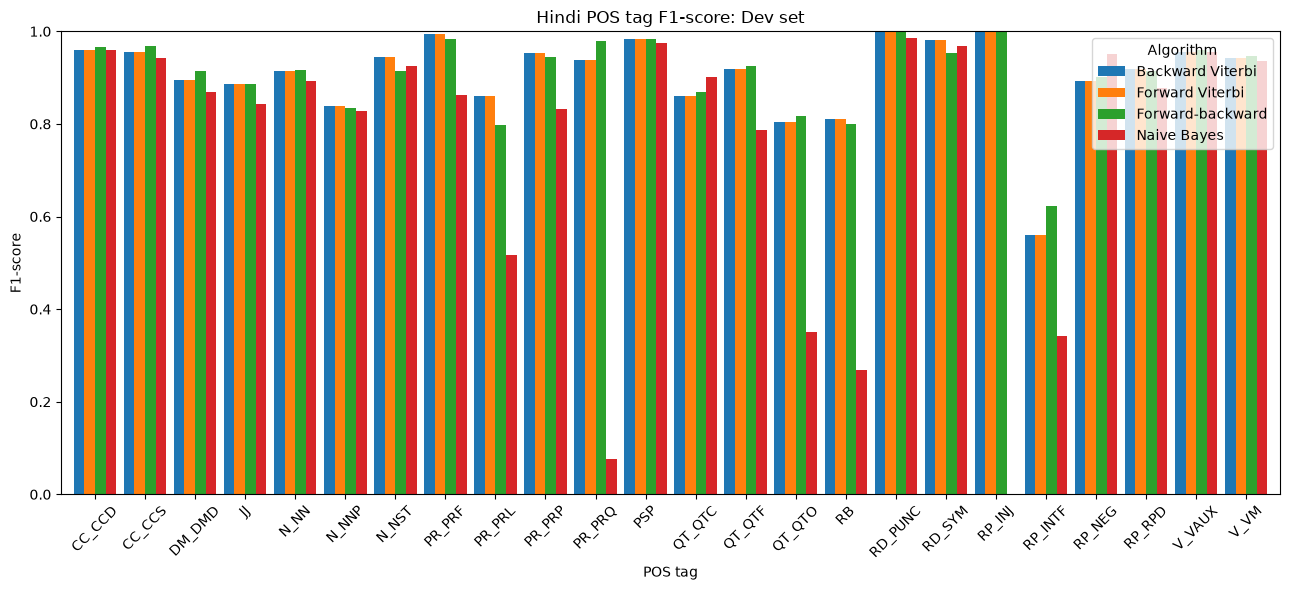

Test results


algorithm,Backward Viterbi,Forward Viterbi,Forward-backward,Naive Bayes
tag,,,,
CC_CCD,0.9507,0.9507,0.9611,0.9687
CC_CCS,0.9526,0.9526,0.9652,0.9553
DM_DMD,0.8955,0.8955,0.9135,0.9126
JJ,0.8992,0.8992,0.9007,0.8529
N_NN,0.9072,0.9072,0.9087,0.8855
N_NNP,0.8411,0.8411,0.8399,0.8274
N_NST,0.9316,0.9316,0.9102,0.9286
PR_PRF,0.9967,0.9967,0.9934,0.8832
PR_PRL,0.8350,0.8350,0.7489,0.5323


                  accuracy  macro_f1
Naive Bayes         0.9104    0.7600
Forward Viterbi     0.9285    0.8675
Backward Viterbi    0.9285    0.8675
Forward-backward    0.9295    0.8635


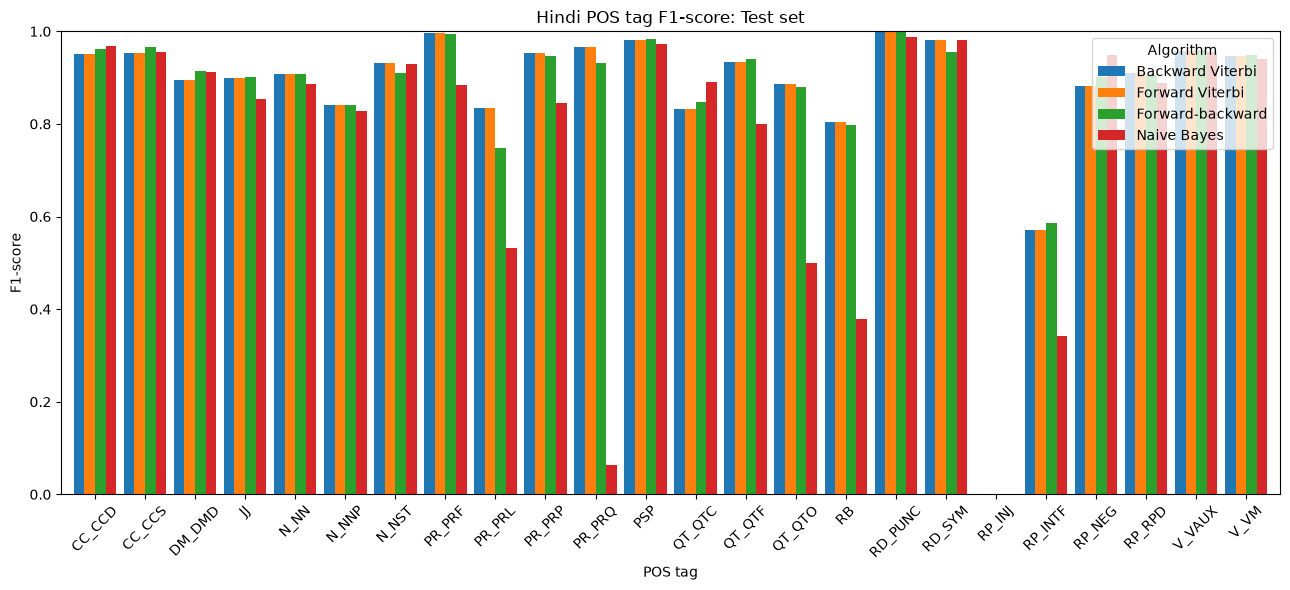

Saved per-tag scores, charts, and summary under E:\STUDY\NLP\Lab 7\outputs.


In [6]:
def evaluate_by_tag(sentences, predictions, label_set):
    true_counts = Counter()
    predicted_counts = Counter()
    correct_counts = Counter()
    total_correct = 0
    total_tokens = 0

    for sentence, predicted_tags in zip(sentences, predictions):
        if len(sentence) != len(predicted_tags):
            raise ValueError("Prediction length does not match sentence length")
        for (_, gold_tag), predicted_tag in zip(sentence, predicted_tags):
            true_counts[gold_tag] += 1
            predicted_counts[predicted_tag] += 1
            if gold_tag == predicted_tag:
                correct_counts[gold_tag] += 1
                total_correct += 1
            total_tokens += 1

    rows = []
    for tag in label_set:
        precision = correct_counts[tag] / predicted_counts[tag] if predicted_counts[tag] else 0.0
        recall = correct_counts[tag] / true_counts[tag] if true_counts[tag] else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        rows.append({"tag": tag, "precision": precision, "recall": recall, "f1": f1, "support": true_counts[tag]})
    return pd.DataFrame(rows), total_correct / total_tokens


algorithm_predictions = {
    "Naive Bayes": (
        [predict_naive_bayes([word for word, _ in sentence], naive_bayes_model) for sentence in dev_sentences],
        [predict_naive_bayes([word for word, _ in sentence], naive_bayes_model) for sentence in test_sentences],
    ),
    "Forward Viterbi": (forward_dev_predictions, forward_test_predictions),
    "Backward Viterbi": (backward_dev_predictions, backward_test_predictions),
    "Forward-backward": (forward_backward_dev_predictions, forward_backward_test_predictions),
}

summary = {}
for split_name, split_index, sentences in [
    ("dev", 0, dev_sentences),
    ("test", 1, test_sentences),
]:
    metric_tables = []
    summary[split_name] = {}
    for algorithm, split_predictions in algorithm_predictions.items():
        metrics, accuracy = evaluate_by_tag(sentences, split_predictions[split_index], tags)
        metrics.insert(1, "algorithm", algorithm)
        metric_tables.append(metrics)
        summary[split_name][algorithm] = {
            "accuracy": accuracy,
            "macro_f1": float(metrics["f1"].mean()),
        }
    results = pd.concat(metric_tables, ignore_index=True)
    results.to_csv(OUTPUT_DIR / f"pos_f1_{split_name}.csv", index=False, encoding="utf-8")
    print(f"{split_name.title()} results")
    display(results.pivot(index="tag", columns="algorithm", values="f1").round(4))
    print(pd.DataFrame(summary[split_name]).T.round(4))

    chart = results.pivot(index="tag", columns="algorithm", values="f1")
    axis = chart.plot(kind="bar", figsize=(13, 6), width=0.85)
    axis.set(title=f"Hindi POS tag F1-score: {split_name.title()} set", xlabel="POS tag", ylabel="F1-score")
    axis.set_ylim(0, 1)
    axis.legend(title="Algorithm")
    axis.tick_params(axis="x", labelrotation=45)
    axis.figure.tight_layout()
    axis.figure.savefig(OUTPUT_DIR / f"pos_f1_comparison_{split_name}.png", dpi=160)
    plt.show()
    plt.close(axis.figure)

(OUTPUT_DIR / "pos_tagging_summary.json").write_text(
    json.dumps(summary, indent=2, ensure_ascii=False) + "\n", encoding="utf-8"
)
print(f"Saved per-tag scores, charts, and summary under {OUTPUT_DIR}.")
